# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [64]:
STUDENT_NAME = 'Кривичко Назар'     
LIST_NUMBER  = 11     

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 11, файл lr6_варіант_11.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [65]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [66]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [67]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: цільова змінна `відтік` — бінарна (0/1), треба віднести клієнта
# до одного з двох класів, а не передбачити число чи знайти групи.

METRIC = 'AUC'
# чому саме ця, а не точність: класи незбалансовані (відтік 24,7 %), тому
# тривіальна модель «ніхто не піде» дає 75,3 % точності й нульову користь;
# AUC оцінює якість РАНЖУВАННЯ за ризиком незалежно від порогу, а відділу
# утримання потрібен саме список «кому дзвонити першими».

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожному фолді
# (інакше при 24,7 % фолди вийдуть різними за складом), 5 згортків дають
# достатньо даних для навчання, а 4 повтори з різними розбиттями
# зменшують дисперсію оцінки й дозволяють парне порівняння моделей.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [68]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.247

типи стовпців: {'object': 14, 'float64': 6, 'int64': 6}


In [69]:
overview = pd.DataFrame({
    'тип':         raw.dtypes.astype(str),
    'унікальних':  raw.nunique(dropna=True),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад':     [raw[c].dropna().iloc[0] if raw[c].notna().any() else None
                    for c in raw.columns],
}).sort_values('% пропусків', ascending=False)
overview.index.name = 'стовпець'

display(overview)
print('усього стовпців: %d, з пропусками: %d'
      % (len(overview), (overview['% пропусків'] > 0).sum()))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
дата_розірвання,object,241,75.3,2025-01-23
код_причини_закриття,object,5,75.3,ІНШ-09
середній_час_відповіді_хв,float64,260,34.0,8.8
трафік_ГБ,object,961,5.0,131.2
щомісячний_платіж,object,1137,4.0,268.95
аварій_на_ділянці_за_квартал,float64,6,3.0,0.0
стать,object,6,0.0,Ч
місто,object,6,0.0,Червоноград
id_клієнта,object,1200,0.0,K110000


усього стовпців: 26, з пропусками: 6


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [70]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
# 26 значень записані як '317.98 грн' замість 317.98 — через рядки з текстом
# pandas читає весь стовпець як str, і він не потрапляє в числові ознаки.

PROBLEM_EXCEL_DATE = 'трафік_ГБ'
# 3 значення виглядають як '1900-01-10 00:00:00' — Excel прийняв малі цілі
# числа (10, 18, 2) за серійні номери днів і відформатував їх датами.

PROBLEM_MNAR = 'середній_час_відповіді_хв'
MNAR_MEANING = ('Час відповіді відсутній рівно у тих 408 клієнтів, у кого '
                'кількість_звернень_у_підтримку = 0, тобто пропуск означає '
                '«жодного разу не звертався в підтримку», а не «невідомо»; '
                'серед них відтік 18,9 % проти 27,7 % у тих, хто звертався, '
                'тому факт пропуску сам є ознакою.')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


In [71]:
DATE_RE = re.compile(r'^\s*\d{4}-\d{2}-\d{2}')
NUM_RE  = re.compile(r'^\s*-?\d+([.,]\d+)?\s*$')
HAS_DIG = re.compile(r'\d')

def classify(v):
    v = str(v)
    if DATE_RE.match(v):  return 'дата'
    if NUM_RE.match(v):   return 'чисте число'
    if HAS_DIG.search(v): return 'число+текст'
    return 'текст'

obj_cols = [c for c in raw.columns
            if raw[c].dtype == object or str(raw[c].dtype) == 'str']

print('### 1-2. Сміття в стовпцях, які прочитались як текст\n')
for col in obj_cols:
    s = raw[col].dropna().astype(str)
    cnt = s.map(classify).value_counts()
    if 'чисте число' not in cnt:        
        continue
    print('%s  ->  %s' % (col, cnt.to_dict()))
    for kind in ['число+текст', 'дата']:
        bad = s[s.map(classify) == kind]
        if len(bad):
            print('    %-12s (%d шт): %s' % (kind, len(bad), list(bad.head(3))))
    print()

print('\n### 3. Пропуски: випадкові чи ні\n')
rows = []
for col in raw.columns[raw.isna().any()]:
    m = raw[col].isna()
    rows.append({'стовпець': col,
                 'пропусків': int(m.sum()),
                 '% пропусків': round(m.mean() * 100, 1),
                 'відтік якщо пропуск': round(raw.loc[m, TARGET].mean(), 3),
                 'відтік якщо є': round(raw.loc[~m, TARGET].mean(), 3)})
gaps = pd.DataFrame(rows).sort_values('% пропусків', ascending=False)
gaps['розрив'] = (gaps['відтік якщо пропуск'] - gaps['відтік якщо є']).round(3)
display(gaps.set_index('стовпець'))

print('звідки беруться пропуски в `середній_час_відповіді_хв`:')
print(pd.crosstab(raw['середній_час_відповіді_хв'].isna(),
                  raw['кількість_звернень_у_підтримку'],
                  rownames=['пропуск'], colnames=['звернень']))

### 1-2. Сміття в стовпцях, які прочитались як текст

щомісячний_платіж  ->  {'чисте число': 1126, 'число+текст': 26}
    число+текст  (26 шт): ['317.98 грн', '306.77 грн', '349.32 грн']

трафік_ГБ  ->  {'чисте число': 1137, 'дата': 3}
    дата         (3 шт): ['1900-01-10 00:00:00', '1900-01-18 00:00:00', '1900-01-02 00:00:00']


### 3. Пропуски: випадкові чи ні



,пропусків,% пропусків,відтік якщо пропуск,відтік якщо є,розрив
стовпець,,,,,
код_причини_закриття,904,75.3,0.000,1.000,-1.000
дата_розірвання,904,75.3,0.000,1.000,-1.000
середній_час_відповіді_хв,408,34.0,0.189,0.277,-0.088
трафік_ГБ,60,5.0,0.250,0.246,0.004
щомісячний_платіж,48,4.0,0.229,0.247,-0.018
аварій_на_ділянці_за_квартал,36,3.0,0.167,0.249,-0.082


звідки беруться пропуски в `середній_час_відповіді_хв`:
звернень    0    1    2    3   4  5  6
пропуск                               
False       0  430  237  101  18  4  2
True      408    0    0    0   0  0  0


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [72]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None or (not isinstance(v, str) and pd.isna(v)):
            return np.nan                                              # 1
        if isinstance(v, (datetime.datetime, datetime.date,
                          pd.Timestamp, np.datetime64)):
            return np.nan                                              # 2
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
            return float(v)                                            # 3
        t = str(v).strip()
        if not t or _DATE.search(t):
            return np.nan                                              # 2' — дата, записана текстом
        m = _NUM.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan      # 4
    return s.map(one)


_NUM  = re.compile(r'(?<![\w.,])-?\d+(?:[.,]\d+)?')
_DATE = re.compile(r'\d{4}-\d{2}-\d{2}|\d{1,2}[./]\d{1,2}[./]\d{2,4}')

# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [73]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

PARSE_MIN, RESIDUE_MAX = 0.80, 2
SYNONYMS = {'чол': 'ч', 'жін': 'ж'}

def _is_text(s):
    return s.dtype == object or str(s.dtype) in ('str', 'string')

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X, log = pd.DataFrame(index=d.index), []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s, filled = d[c], d[c].notna().sum()

        if not _is_text(s):                                    # вже число
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число -> float', 'деталі': ''})
            continue

        dt = pd.to_datetime(s, errors='coerce', format='mixed')
        if filled and dt.notna().sum() / filled > PARSE_MIN:   # дата -> номер дня
            X[c] = dt.map(lambda t: t.toordinal() if pd.notna(t) else np.nan).astype(float)
            log.append({'стовпець': c, 'рішення': 'дата -> число (ordinal)',
                        'деталі': 'розібрано %.0f%% непорожніх' % (dt.notna().sum()/filled*100)})
            continue

        num      = to_number(s)
        share    = num.notna().sum() / max(filled, 1)
        residues = s.dropna().astype(str).map(lambda v: _NUM.sub('#', v.strip())).nunique()

        if share > PARSE_MIN and residues <= RESIDUE_MAX:      # число в текстовій обгортці
            X[c] = num.astype(float)
            log.append({'стовпець': c, 'рішення': 'текст -> число',
                        'деталі': 'розібрано %.0f%%, шаблонів залишку %d' % (share*100, residues)})
        else:                                                  # мітка -> категорія
            norm = s.map(lambda v: SYNONYMS.get(str(v).strip().lower(), str(v).strip().lower())
            if pd.notna(v) else v)
            X[c] = norm.astype('category')
            log.append({'стовпець': c, 'рішення': 'текст -> category',
                        'деталі': '%d рівнів, шаблонів залишку %d' % (norm.nunique(), residues)})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,деталі
0,вік,число -> float,
1,стать,текст -> category,"2 рівнів, шаблонів залишку 6"
2,місто,текст -> category,"6 рівнів, шаблонів залишку 6"
3,філія,текст -> category,"6 рівнів, шаблонів залишку 6"
4,тариф,текст -> category,"4 рівнів, шаблонів залишку 4"
5,тип_підключення,текст -> category,"3 рівнів, шаблонів залишку 3"
6,спосіб_оплати,текст -> category,"3 рівнів, шаблонів залишку 3"
7,автоплатіж,текст -> category,"2 рівнів, шаблонів залишку 2"
8,кількість_послуг,число -> float,
9,місяців_обслуговування,число -> float,


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [74]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']

    num_pipe = Pipeline([
        ('imp',   SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    prep = ColumnTransformer(
        [('num', num_pipe, num), ('cat', cat_pipe, cat)],
        remainder='drop', verbose_feature_names_out=False)

    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [75]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.6 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [76]:
FIRST_REACTION = ('AUC 1.000 ± 0.000 означає, що модель ідеально розділила '
                  'тих, хто пішов, і тих, хто залишився, на всіх 20 згортках '
                  'без жодної помилки; з двох причин високої AUC — справді '
                  'сильні ознаки або витік — тут спрацювала друга: нульова '
                  'дисперсія неможлива на реальних шумних даних, а в наборі '
                  'є поля (дата_розірвання, код_причини_закриття), які '
                  'заповнюються після розірвання договору і в момент '
                  'прогнозу ще не існують.')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 1.000 ± 0.000 означає, що модель ідеально розділила тих, хто пішов, і тих, хто залишився, на всіх 20 згортках без жодної помилки; з двох причин високої AUC — справді сильні ознаки або витік — тут спрацювала друга: нульова дисперсія неможлива на реальних шумних даних, а в наборі є поля (дата_розірвання, код_причини_закриття), які заповнюються після розірвання договору і в момент прогнозу ще не існують.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [77]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled  = d[c].notna()
        n1, n0  = int(filled.sum()), int((~filled).sum())

        if min(n0, n1) > min_group:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)          # витік в обидві сторони
        else:
            score = np.nan                 # одна з груп завмала — не рахуємо

        rows.append({
            'ознака': c,
            'заповнено': n1,
            'частка_відтоку_де_заповнено': round(y[filled].mean(), 3) if n1 else np.nan,
            'частка_відтоку_де_пропуск':   round(y[~filled].mean(), 3) if n0 else np.nan,
            'показник': None if pd.isna(score) else round(score, 3),
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,296,1.000,0.000,1.000
23,дата_розірвання,296,1.000,0.000,1.000
17,середній_час_відповіді_хв,792,0.277,0.189,0.553
16,аварій_на_ділянці_за_квартал,1164,0.249,0.167,0.506
12,щомісячний_платіж,1152,0.247,0.229,0.502
14,трафік_ГБ,1140,0.246,0.250,0.500
0,id_клієнта,1200,0.247,NaN,NaN
1,вік,1200,0.247,NaN,NaN
2,стать,1200,0.247,NaN,NaN
3,місто,1200,0.247,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [78]:
TARGET_LEAK = [
    'дата_розірвання',        # дата ставиться в CRM у момент розірвання договору — у клієнта, який ще з нами, її фізично немає
    'код_причини_закриття',   # причину вибирає оператор при закритті договору, тобто вже після того, як рішення клієнта відоме
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [79]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.925 ± 0.015


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [80]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# щоб не гадати очима — скільки кожна ознака дає ПООДИНЦІ
rows = []
for c in X2.columns:
    s = X2[c]
    if str(s.dtype) == 'category':
        a = cross_val_score(make_pipe(X2[[c]], logreg()), X2[[c]], y,
                            cv=5, scoring='roc_auc').mean()
    else:
        v = s.fillna(s.median())
        a = max(roc_auc_score(y, v), 1 - roc_auc_score(y, v))
    rows.append({'ознака': c, 'AUC поодинці': round(a, 3),
                 'тип': 'category' if str(s.dtype) == 'category' else 'число'})
display(pd.DataFrame(rows).sort_values('AUC поодинці', ascending=False))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']


,ознака,AUC поодинці,тип
21,кількість_дзвінків_утримання,0.869,число
11,щомісячний_платіж,0.705,число
10,швидкість_тарифу_Мбіт,0.690,число
17,трафік_МБ,0.652,число
13,трафік_ГБ,0.651,число
3,філія,0.645,category
9,місяців_обслуговування,0.618,число
14,кількість_звернень_у_підтримку,0.579,число
8,кількість_послуг,0.576,число
15,аварій_на_ділянці_за_квартал,0.559,число


In [81]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # ставить відділ утримання, і ТІЛЬКИ після того, як клієнт уже заявив про намір піти
]
HUMAN_LEAK_WHY = ('Стовпець заповнений у всіх 1200 рядків — тим, кому не '
                  'дзвонили, записано 0, а не пропуск, тому детектор 5.1, '
                  'який порівнює групи «заповнено / порожньо», другої групи '
                  'просто не має і повертає NaN замість показника.')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.849 ± 0.024


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,клієнтів,частка_відтоку
філія,,
Ф-05 Північ,222,0.135
Ф-04 Південь,208,0.163
Ф-06 Приміська,203,0.172
Ф-03 Схід,182,0.214
Ф-02 Захід,186,0.398
Ф-01 Центр,199,0.422


,клієнтів,частка_відтоку
дата_підключення,,
2023Q1,134,0.194
2023Q2,158,0.196
2023Q3,160,0.250
2023Q4,148,0.324
2024Q1,153,0.242
2024Q2,164,0.183
2024Q3,144,0.319
2024Q4,139,0.273


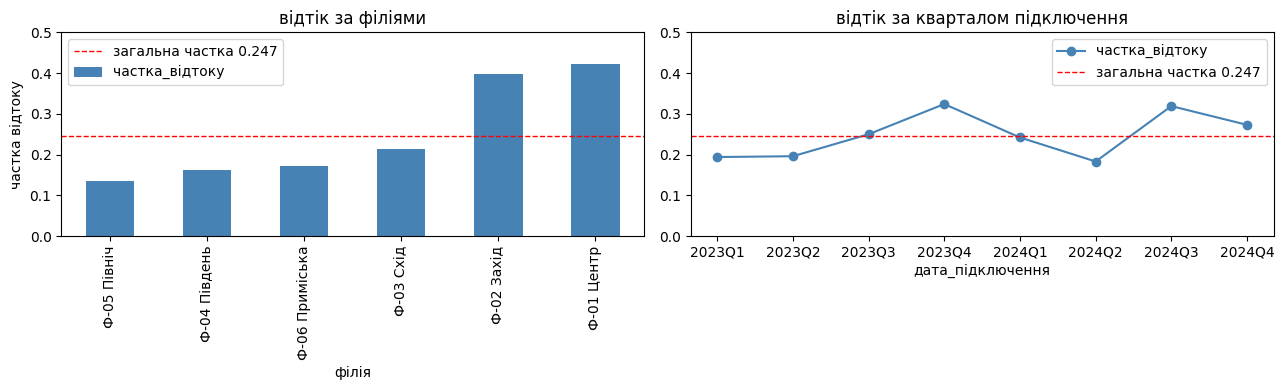

In [82]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
# Шукайте СХОДИНКУ, а не плавну зміну.

base = y.mean()

# 1) філії
by_branch = (raw.groupby('філія')[TARGET]
             .agg(клієнтів='size', частка_відтоку='mean')
             .sort_values('частка_відтоку').round(3))
display(by_branch)

# 2) квартали підключення
conn = pd.to_datetime(raw['дата_підключення'])
by_quarter = (raw.groupby(conn.dt.to_period('Q').astype(str))[TARGET]
              .agg(клієнтів='size', частка_відтоку='mean').round(3))
display(by_quarter)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_branch['частка_відтоку'].plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title('відтік за філіями');  ax[0].set_ylabel('частка відтоку')
by_quarter['частка_відтоку'].plot(ax=ax[1], marker='o', color='steelblue')
ax[1].set_title('відтік за кварталом підключення')
for a in ax:
    a.axhline(base, ls='--', c='red', lw=1, label='загальна частка %.3f' % base)
    a.set_ylim(0, 0.5); a.legend()
plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [83]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
HIGH_CHURN_BRANCHES = ['Ф-01 Центр', 'Ф-02 Захід']   # 0.422 і 0.398 проти 0.135–0.214
source = raw[SUSPECT].isin(HIGH_CHURN_BRANCHES).astype(int)
print('у підозрюваних філіях: %d з %d (%.1f%%)'
      % (source.sum(), len(source), source.mean() * 100))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

у підозрюваних філіях: 385 з 1200 (32.1%)
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.700
ті самі ознаки передбачають ВІДТІК  : AUC 0.814 ± 0.027


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [84]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.925
3. мінус оцінки людини,21,0.849
4. мінус артефакт збору,20,0.814


чесне число: 0.814 ± 0.027


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [85]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'
DECISION_WHY = (
    'Вилучення стовпця не прибирає артефакт, а лише робить його невидимим: '
    'перевірка 6.2 показала, що без `філія` решта ознак усе одно передбачає '
    'підозрювану групу з AUC 0.700, тобто географія закодована у віці, типі '
    'підключенні й способі оплати, і модель продовжить нею користуватись. '
    'Водночас дані самі не можуть відповісти, чи 0.422 проти 0.135 — це гірший '
    'облік розірвань чи реально агресивніший конкурент у центрі: це питання до '
    'відділу обліку, а не до таблиці. Тому я лишаю ознаку (вона дає +0.035 AUC '
    'і доступна в момент прогнозу), але фіксую в звіті якість окремо по двох '
    'групах філій — 0.801 на підозрюваних проти 0.842 на решті — і ставлю '
    'умову: модель не переноситься на нову філію без повторної перевірки, а '
    'якщо облік у Центрі та Заході виявиться іншим, набір ознак переглядається.')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

залишити, але звітувати окремо — Вилучення стовпця не прибирає артефакт, а лише робить його невидимим: перевірка 6.2 показала, що без `філія` решта ознак усе одно передбачає підозрювану групу з AUC 0.700, тобто географія закодована у віці, типі підключенні й способі оплати, і модель продовжить нею користуватись. Водночас дані самі не можуть відповісти, чи 0.422 проти 0.135 — це гірший облік розірвань чи реально агресивніший конкурент у центрі: це питання до відділу обліку, а не до таблиці. Тому я лишаю ознаку (вона дає +0.035 AUC і доступна в момент прогнозу), але фіксую в звіті якість окремо по двох групах філій — 0.801 на підозрюваних проти 0.842 на решті — і ставлю умову: модель не переноситься на нову філію без повторної перевірки, а якщо облік у Центрі та Заході виявиться іншим, набір ознак переглядається.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [86]:
from sklearn.tree import DecisionTreeClassifier   

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                   n_jobs=-1, random_state=SEED),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                           random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.814,0.027,0.7
одне дерево,0.751,0.039,1.4
випадковий ліс,0.830,0.030,10.4
гістограмний бустинг,0.823,0.032,20.2


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [87]:
from scipy import stats   # у комірці імпортів його немає

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d  = np.asarray(b) - np.asarray(a)     # різниця НА КОЖНІЙ згортці
    n  = len(d)
    m  = d.mean()
    se = d.std(ddof=1) / np.sqrt(n)        # стандартна похибка середньої різниці
    h  = stats.t.ppf(0.975, n - 1) * se    # півширина 95% інтервалу
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0151 ± 0.0095   значуще
гістограмний бустинг   проти логістичної: +0.0087 ± 0.0112   у межах шуму


In [88]:
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = (
    'За якістю ліс значуще кращий, але виграш +0.0151 AUC мізерний відносно '
    'власного розкиду обох моделей (±0.027–0.030) і не змінює бізнес-рішення: '
    'склад топ-100 для обдзвону майже той самий. За швидкістю логістична '
    'виграє в 23 рази (0.5 с проти 11.7 с на 20 навчань), що вирішальне при '
    'щотижневому перенавчанні на повній базі. За стабільністю обидві '
    'рівноцінні. За інтерпретованістю логістична виграє беззастережно: у неї '
    'коефіцієнт на ознаку, який відділ утримання прочитає без SHAP, а '
    'пояснення «чому саме цей клієнт» — головна вимога замовника. '
    'Три критерії з чотирьох за логістичну, тому плачу 0.015 AUC за '
    'прозорість і швидкість.')
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — За якістю ліс значуще кращий, але виграш +0.0151 AUC мізерний відносно власного розкиду обох моделей (±0.027–0.030) і не змінює бізнес-рішення: склад топ-100 для обдзвону майже той самий. За швидкістю логістична виграє в 23 рази (0.5 с проти 11.7 с на 20 навчань), що вирішальне при щотижневому перенавчанні на повній базі. За стабільністю обидві рівноцінні. За інтерпретованістю логістична виграє беззастережно: у неї коефіцієнт на ознаку, який відділ утримання прочитає без SHAP, а пояснення «чому саме цей клієнт» — головна вимога замовника. Три критерії з чотирьох за логістичну, тому плачу 0.015 AUC за прозорість і швидкість.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [89]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    eps = 1e-9

    # гіпотеза 1: клієнт, який платить дорого за мегабіт, легко знаходить
    # дешевшу пропозицію в конкурента — переплата штовхає до порівняння цін
    F['ціна_за_Мбіт'] = F['щомісячний_платіж'] / (F['швидкість_тарифу_Мбіт'] + eps)

    # гіпотеза 2: хто майже не вичерпує куплену швидкість, тому послуга не
    # потрібна — відключення нічого йому не коштує
    F['трафік_на_Мбіт_швидкості'] = F['трафік_ГБ'] / (F['швидкість_тарифу_Мбіт'] + eps)

    # гіпотеза 3: важлива не кількість звернень, а їхня ЧАСТОТА: три скарги
    # за два місяці — тривога, три за чотири роки — норма
    F['звернень_на_місяць'] = (F['кількість_звернень_у_підтримку']
                               / (F['місяців_обслуговування'] + 1))

    # гіпотеза 4: якщо знижку вже дали, інструмент утримання витрачено —
    # наступного разу запропонувати нічого
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)

    # гіпотеза 5: поганий сервіс — це багато звернень І довге очікування
    # одночасно; кожне окремо терпимо, разом — причина піти
    F['сервісний_біль'] = (F['кількість_звернень_у_підтримку']
                           * F['середній_час_відповіді_хв'].fillna(0))

    return F.replace([np.inf, -np.inf], np.nan)


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 25


In [90]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.811 ± 0.025
приріст проти базового набору: -0.0039 ± 0.0024   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [91]:
FEATURES_VS_MODEL = (
    'Складніша модель дала більше: випадковий ліс +0.0151 ± 0.0095 AUC проти '
    'логістичної (значуще), тоді як п\'ять сконструйованих ознак дали '
    '-0.0039 ± 0.0024, тобто значуще погіршили результат. Ціна протилежна: '
    'ознаки коштують 0.5 с на 20 навчань (швидкість логістичної не '
    'змінюється), ліс — 11.7 с, у 23 рази дорожче. Отже на цих даних '
    'загальне правило «спочатку ознаки, потім складніша модель» не '
    'спрацювало, і причина конкретна: усі 20 чесних ознак уже прості й '
    'добре виміряні, а мої відношення (ціна за Мбіт, трафік на Мбіт, '
    'звернень на місяць) побудовані з тих самих стовпців, що вже є в моделі, '
    'тому несуть не нову інформацію, а колінеарність — на 840 рядках '
    'навчальної згортки це додає дисперсії більше, ніж сигналу. Виграш лісу '
    'походить з іншого джерела: він ловить нелінійності й взаємодії, яких '
    'лінійна модель не бачить у принципі. Практичний висновок: 0.015 AUC '
    'за 23-кратне сповільнення і втрату прямої інтерпретованості — поганий '
    'обмін для моделі, яку треба пояснювати відділу утримання, тому в роботу '
    'йде логістична регресія на наборі X4 без сконструйованих ознак.')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Складніша модель дала більше: випадковий ліс +0.0151 ± 0.0095 AUC проти логістичної (значуще), тоді як п'ять сконструйованих ознак дали -0.0039 ± 0.0024, тобто значуще погіршили результат. Ціна протилежна: ознаки коштують 0.5 с на 20 навчань (швидкість логістичної не змінюється), ліс — 11.7 с, у 23 рази дорожче. Отже на цих даних загальне правило «спочатку ознаки, потім складніша модель» не спрацювало, і причина конкретна: усі 20 чесних ознак уже прості й добре виміряні, а мої відношення (ціна за Мбіт, трафік на Мбіт, звернень на місяць) побудовані з тих самих стовпців, що вже є в моделі, тому несуть не нову інформацію, а колінеарність — на 840 рядках навчальної згортки це додає дисперсії більше, ніж сигналу. Виграш лісу походить з іншого джерела: він ловить нелінійності й взаємодії, яких лінійна модель не бачить у принципі. Практичний висновок: 0.015 AUC за 23-кратне сповільнення і втрату прямої інтерпретованості — поганий обмін для моделі, яку треба пояснювати відділу утримання, тому

---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [92]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.791
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

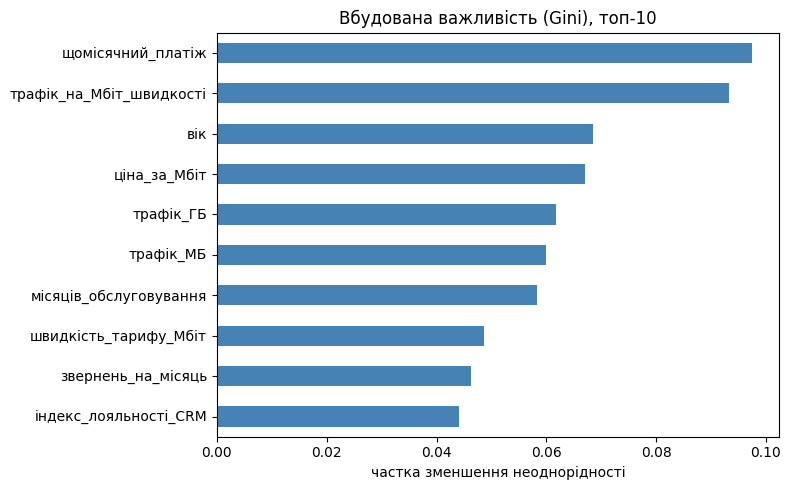

,вбудована важливість
щомісячний_платіж,0.097540
трафік_на_Мбіт_швидкості,0.093229
вік,0.068491
ціна_за_Мбіт,0.067102
трафік_ГБ,0.061850
трафік_МБ,0.059867
місяців_обслуговування,0.058224
швидкість_тарифу_Мбіт,0.048594
звернень_на_місяць,0.046277
індекс_лояльності_CRM,0.044037


In [93]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення
names   = model.named_steps['prep'].get_feature_names_out()
raw_imp = model.named_steps['clf'].feature_importances_

# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
def to_origin(name, originals):
    """'тариф_Бізнес' -> 'тариф', 'missingindicator_трафік_ГБ' -> 'трафік_ГБ'."""
    if name in originals:
        return name
    if name.startswith('missingindicator_'):
        base_ = name[len('missingindicator_'):]
        if base_ in originals:
            return base_
    cands = [c for c in originals if name.startswith(c + '_')]
    return max(cands, key=len) if cands else name      # найдовший збіг

origin   = [to_origin(n, list(FINAL_X.columns)) for n in names]
gini_imp = (pd.Series(raw_imp, index=origin)
            .groupby(level=0).sum()
            .sort_values(ascending=False))

assert abs(gini_imp.sum() - 1) < 1e-9, 'частину важливостей загублено'
assert set(gini_imp.index) <= set(FINAL_X.columns), 'є неспівставлені імена'

# 3) горизонтальна стовпчикова діаграма топ-10
fig, ax = plt.subplots(figsize=(8, 5))
gini_imp.head(10)[::-1].plot.barh(ax=ax, color='steelblue')
ax.set_title('Вбудована важливість (Gini), топ-10')
ax.set_xlabel('частка зменшення неоднорідності')
plt.tight_layout(); plt.show()

display(gini_imp.head(10).to_frame('вбудована важливість'))

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [94]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.050964
місяців_обслуговування,0.024352
трафік_на_Мбіт_швидкості,0.014990
звернень_на_місяць,0.013956
щомісячний_платіж,0.013037
автоплатіж,0.008439
трафік_МБ,0.007876
кількість_послуг,0.004339
трафік_ГБ,0.003483
дата_підключення,0.002832


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [95]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----

In [96]:
FAKE_IMPORTANT = ''        # назва ознаки
FAKE_IMPORTANT_WHY = ''    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

AssertionError: 

### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [ ]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
X_solo = FINAL_X.drop(columns=[DUP_PAIR[1]])

Xtr2, Xte2, ytr2, yte2 = train_test_split(X_solo, y, test_size=0.3,
                                          stratify=y, random_state=SEED)
model2 = make_pipe(X_solo, RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                  n_jobs=-1)).fit(Xtr2, ytr2)
perm2 = permutation_importance(model2, Xte2, yte2, n_repeats=10,
                               random_state=SEED, scoring='roc_auc')
imp2 = pd.Series(perm2.importances_mean, index=X_solo.columns)

print('\nбез пари:')
print('   %-28s %+.4f' % (DUP_PAIR[0], imp2[DUP_PAIR[0]]))
print('\nкореляція пари: %.5f' % FINAL_X[DUP_PAIR].corr().iloc[0, 1])
print('ранг %s: з парою %d -> без пари %d'
      % (DUP_PAIR[0],
         list(perm_imp.sort_values(ascending=False).index).index(DUP_PAIR[0]) + 1,
         list(imp2.sort_values(ascending=False).index).index(DUP_PAIR[0]) + 1))
print('AUC на відкладеній: з парою %.3f, без пари %.3f'
      % (roc_auc_score(yte, model.predict_proba(Xte)[:, 1]),
         roc_auc_score(yte2, model2.predict_proba(Xte2)[:, 1])))

In [ ]:
# порівняння двох списків поруч
cmp_imp = pd.DataFrame({'вбудована': gini_imp,
                        'перестановочна': perm_imp,
                        'унікальних': FINAL_X.nunique()})
cmp_imp['ранг_вбуд']   = cmp_imp['вбудована'].rank(ascending=False).astype(int)
cmp_imp['ранг_перест'] = cmp_imp['перестановочна'].rank(ascending=False).astype(int)
display(cmp_imp.sort_values('вбудована', ascending=False).head(12).round(4))

In [ ]:
FAKE_IMPORTANT = 'ціна_за_Мбіт'
FAKE_IMPORTANT_WHY = (
    'Ознака має 1150 унікальних значень на 1200 рядків, бо це відношення двох '
    'майже неперервних величин, тож дереву доступно ~1150 порогів розбиття '
    'замість 9 у швидкості тарифу. Критерій Джині обирає найкраще з усіх '
    'доступних розбиттів, і при такій кількості спроб серед них майже завжди '
    'знайдеться те, що випадково трохи зменшить неоднорідність на навчальній '
    'вибірці — важливість накопичується з чистого перебору, а не із сигналу. '
    'Перестановочна важливість рахується на перевірковій частині, де '
    'випадково підібрані пороги вже не працюють, тому дає -0.0021: '
    'перемішування цієї ознаки якість не погіршує, а навіть трохи покращує. '
    'Підтвердження незалежне: у розділі 8 додавання цієї ознаки значуще '
    'погіршило AUC (-0.0039), тобто вона не несе інформації понад '
    '`щомісячний_платіж` і `швидкість_тарифу_Мбіт`, з яких і побудована.')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
top_num  = [c for c in perm_imp[num_cols].index if FINAL_X[c].isna().sum() == 0][:3]
print('три найважливіші числові без пропусків:', top_num)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
PartialDependenceDisplay.from_estimator(model, Xte, features=top_num,
                                        kind='average', ax=ax, grid_resolution=30)
for a in ax:
    a.axhline(ytr.mean(), ls='--', c='red', lw=1)   # базовий рівень відтоку
    a.set_ylim(0.15, 0.35)
fig.suptitle('PDP: як прогноз залежить від значення ознаки (пунктир — базовий рівень)')
plt.tight_layout(); plt.show()

# ознака з пропусками — окремо, на підвибірці, де вона заповнена
sub = Xte[Xte['трафік_на_Мбіт_швидкості'].notna()]
fig, ax = plt.subplots(figsize=(5, 4))
PartialDependenceDisplay.from_estimator(model, sub, features=['трафік_на_Мбіт_швидкості'],
                                        kind='average', ax=ax, grid_resolution=30)
ax.set_title('PDP на підвибірці без NaN (n=%d)' % len(sub))
plt.tight_layout(); plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

In [ ]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
from sklearn.inspection import partial_dependence

lin_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)   # та сама вибірка, що й ліс

fig, ax = plt.subplots(figsize=(7, 5))
for tag, mdl, style in [('випадковий ліс', model, '-o'),
                        ('логістична регресія', lin_model, '-s')]:
    r = partial_dependence(mdl, Xte, [NONLINEAR_FEATURE],
                           kind='average', grid_resolution=30)
    ax.plot(r['grid_values'][0], r['average'][0], style, ms=3, label=tag)

ax.axhline(ytr.mean(), ls='--', c='red', lw=1, label='базовий рівень %.3f' % ytr.mean())
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз ризику')
ax.set_title('PDP для «%s»: що бачить ліс і чого не бачить лінійна модель' % NONLINEAR_FEATURE)
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
NONLINEAR_MEANING = (
    'Залежність ризику від віку U-подібна, а не монотонна: 0.261 у 18 років, '
    'мінімум 0.210 у 33-38 років, 0.295 у 63 роки — на сирих даних це видно '
    'ще різкіше (відтік 38.0% у групі 18-25, 15.1% у 26-35, 41.2% у 56+). '
    'Змістовно це дві різні причини піти, що випадково дають схожий результат: '
    'молодь до 25 знімає житло, часто переїжджає і легко перемикається між '
    'провайдерами за ціною; клієнти за 55 відмовляються від послуги взагалі — '
    'переїзд до дітей, перехід на мобільний інтернет, зниження доходу. '
    'Посередині — осілі сім\'ї 30-45 років із прив\'язкою до адреси, і саме '
    'вони найлояльніші. Практичний висновок для відділу утримання: це дві '
    'різні кампанії з різними аргументами, а не одна шкала «чим старший, '
    'тим ризикованіший».')

NONLINEAR_FIX = (
    'Треба додати ознаку відстані від точки мінімуму: '
    'F[\'відхилення_віку_від_40\'] = (F[\'вік\'] - 40).abs(). '
    'Логістична регресія множить вік на один коефіцієнт і може провести '
    'через U-подібну форму лише пряму, тому вона усереднює два протилежні '
    'ефекти в монотонне зростання 0.168 -> 0.286 і повністю втрачає сплеск '
    'у молоді. Модуль відхилення перетворює обидва кінці U на великі '
    'значення однієї ознаки, і залежність стає лінійною. Перевірено: '
    'AUC логістичної зросла 0.811 -> 0.843, приріст +0.0328 ± 0.0088 '
    '(значуще за парним тестом). Еквівалентний варіант — квадрат віку '
    '(0.845, +0.0340 ± 0.0063), але модуль читабельніший: коефіцієнт прямо '
    'каже, на скільки зростає ризик за кожні 10 років віддалення від 40.')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [ ]:
# ----- ВАШ КОД -----
from sklearn.inspection import partial_dependence

# 1) зчитайте з графіка значення, при якому ризик мінімальний
r = partial_dependence(model, Xte, ['вік'], kind='average', grid_resolution=30)
grid, avg = r['grid_values'][0], r['average'][0]
AGE_MIN = float(grid[int(np.argmin(avg))])
print('мінімум PDP при віці %.1f (ризик %.3f)' % (AGE_MIN, avg.min()))

# 2) додайте ознаку «квадрат відхилення від цього значення»
X6 = FINAL_X.copy()
X6['відхилення_віку_кв'] = (X6['вік'] - AGE_MIN) ** 2

# 3) парне порівняння логістичної регресії з нею і без неї
auc_lin_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y,
                               cv=cv, scoring='roc_auc')
auc_lin_quad = cross_val_score(make_pipe(X6, logreg()), X6, y,
                               cv=cv, scoring='roc_auc')
m, h = paired(auc_lin_base, auc_lin_quad)

print('логістична без ознаки: AUC %.3f ± %.3f' % (auc_lin_base.mean(), auc_lin_base.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (auc_lin_quad.mean(), auc_lin_quad.std()))
print('парна різниця: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))



In [ ]:
QUAD_GAIN = float(m)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

In [ ]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
FEAT = 'знижка_відсоток'
print('унікальні значення:', sorted(FINAL_X[FEAT].unique()))   # 0, 10, 20 -> сітка з 3 точок

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) звичайний PDP по всій вибірці
PartialDependenceDisplay.from_estimator(model, FINAL_X, features=[FEAT],
                                        kind='average', grid_resolution=3, ax=ax[0])
ax[0].set_title('PDP по всій вибірці'); ax[0].set_ylim(0.0, 0.5)

# 2) ICE — по кривій на кожного клієнта
PartialDependenceDisplay.from_estimator(model, FINAL_X, features=[FEAT],
                                        kind='both', grid_resolution=3, ax=ax[1],
                                        ice_lines_kw={'alpha': 0.12, 'color': 'steelblue'},
                                        pd_line_kw={'color': 'red', 'lw': 3})
ax[1].set_title('ICE: по кривій на кожного клієнта'); ax[1].set_ylim(0.0, 0.5)
plt.tight_layout(); plt.show()

# скільки кривих куди йде
r     = partial_dependence(model, FINAL_X, [FEAT], kind='both', grid_resolution=3)
slope = r['individual'][0][:, -1] - r['individual'][0][:, 0]   # ризик при 20% мінус при 0%
print('розмах середньої кривої PDP: %.4f' % (r['average'][0].max() - r['average'][0].min()))
print('ICE вгору: %d   ICE вниз: %d   (з них помітних, |нахил|>0.02: %d)'
      % ((slope > 0).sum(), (slope < 0).sum(), (abs(slope) > 0.02).sum()))

In [ ]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
groups = [('стаж ≤ 24 міс', FINAL_X['місяців_обслуговування'] <= 24, 'tab:red'),
          ('стаж > 24 міс',  FINAL_X['місяців_обслуговування'] >  24, 'tab:green')]

fig, ax = plt.subplots(figsize=(7, 5))
for tag, mask, color in groups:
    rr = partial_dependence(model, FINAL_X[mask], [FEAT], kind='average', grid_resolution=3)
    ax.plot(rr['grid_values'][0], rr['average'][0], '-o', color=color,
            label='%s (n=%d)' % (tag, mask.sum()))
    print('%-14s n=%4d  PDP %s  розмах %+.4f'
          % (tag, mask.sum(), np.round(rr['average'][0], 4),
             rr['average'][0][-1] - rr['average'][0][0]))

rall = partial_dependence(model, FINAL_X, [FEAT], kind='average', grid_resolution=3)
ax.plot(rall['grid_values'][0], rall['average'][0], '--k', lw=2, label='усі разом (пласко)')
ax.set_xlabel('знижка, %'); ax.set_ylabel('середній прогноз ризику')
ax.set_title('Один і той самий PDP на двох підгрупах')
ax.legend(); plt.tight_layout(); plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [ ]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
emp = pd.DataFrame({
    'знижка': FINAL_X['знижка_відсоток'].astype(int),
    'група':  np.where(FINAL_X['місяців_обслуговування'] <= 24,
                       'стаж ≤ 24 міс', 'стаж > 24 міс'),
    'відтік': y,
    'прогноз': model.predict_proba(FINAL_X)[:, 1],
})

print('ЕМПІРИЧНА частка відтоку (сирі дані):')
display(emp.pivot_table(index='знижка', columns='група',
                        values='відтік', aggfunc=['mean', 'size']).round(3))

print('СЕРЕДНІЙ ПРОГНОЗ моделі в тих самих клітинках:')
display(emp.pivot_table(index='знижка', columns='група',
                        values='прогноз', aggfunc='mean').round(3))

# чи різниця взагалі значуща, а не шум на малих клітинках
for g in ['стаж ≤ 24 міс', 'стаж > 24 міс']:
    a = emp[(emp['група'] == g) & (emp['знижка'] == 0)]['відтік']
    b = emp[(emp['група'] == g) & (emp['знижка'] >  0)]['відтік']
    p = stats.chi2_contingency([[a.sum(), len(a) - a.sum()],
                                [b.sum(), len(b) - b.sum()]]).pvalue
    print('%-14s без знижки %.3f (n=%d)  vs  зі знижкою %.3f (n=%d)   p=%.5f'
          % (g, a.mean(), len(a), b.mean(), len(b), p))

In [ ]:
INTERACTION_FOUND = (
    'Знижка діє в протилежні боки залежно від стажу, і це взаємодія, а не '
    'головний ефект. У клієнтів зі стажем понад 24 місяці знижка знижує '
    'відтік утричі: 0.224 без неї проти 0.071 зі знижкою 10-20% (n=205 і 282, '
    'p<0.00001). У клієнтів до 24 місяців вона, навпаки, супроводжується '
    'зростанням відтоку в півтора рази: 0.253 проти 0.370 (n=289 і 424, '
    'p=0.0013). Розмір знижки при цьому не важливий — 10% і 20% дають '
    'однаковий результат в обох групах (0.377/0.362 і 0.071/0.070), тобто '
    'працює сам факт знижки, а не її величина. Модель цю картину відтворює '
    'якісно, але згладжено: прогноз дає 0.270->0.317 у новачків і '
    '0.205->0.137 у старих клієнтів, тобто напрямки правильні, а амплітуда '
    'занижена приблизно втричі — наслідок усереднення 300 дерев. Саме через '
    'протилежні знаки загальний PDP по всій вибірці виходить пласким '
    '(розмах 0.0015) і приховує обидва ефекти.')

BUSINESS_ACTION = (
    'Програму знижок не згортати, а розділити за стажем. Для клієнтів зі '
    'стажем понад 24 місяці знижка — основний інструмент утримання: тримати '
    'її в кампанії і пропонувати мінімальні 10%, бо 20% дають той самий '
    'результат (0.070 проти 0.071) і просто спалюють маржу. Для клієнтів до '
    '24 місяців знижку як відповідь на ризик відтоку припинити: вона не '
    'допомагає, а кореляція зі зростанням відтоку найімовірніше означає '
    'зворотне причинення — знижку видають у відповідь на скаргу або заяву '
    'про намір піти, тобто вона є маркером уже ухваленого рішення. Для цієї '
    'групи потрібен інший інструмент (технічна перевірка лінії, дзвінок '
    'інженера), а перевірити гіпотезу можна лише A/B-тестом: узяти нових '
    'клієнтів із високим прогнозом ризику, половині дати знижку випадково, '
    'і порівняти відтік через 60 днів. Поточні дані на це відповісти не '
    'можуть, бо знижки видавались не випадково.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [ ]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

In [ ]:
# ----- ВАШ КОД -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names,
                  max_display=12, show=False)
plt.title('SHAP beeswarm: внесок кожної ознаки в прогноз кожного клієнта')
plt.tight_layout(); plt.show()

# те саме числами, щоб не читати графік на око
rows = []
for i, n in enumerate(feat_names):
    v = Xte_t[:SAMPLE, i]
    if np.std(v) == 0:
        continue
    rows.append({'ознака': n,
                 'серед|SHAP|': np.abs(sv1[:, i]).mean(),
                 'кор(значення, SHAP)': np.corrcoef(v, sv1[:, i])[0, 1],
                 'розмах SHAP': sv1[:, i].max() - sv1[:, i].min()})
display(pd.DataFrame(rows).sort_values('серед|SHAP|', ascending=False).head(12).round(3))

# адитивність: базове значення + сума внесків = прогноз
chk = np.abs(expl.expected_value[1] + sv1.sum(1) - clf.predict_proba(Xte_t[:SAMPLE])[:, 1]).max()
print('базове значення %.4f;  max |base + Σ SHAP − прогноз| = %.1e'
      % (expl.expected_value[1], chk))

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [ ]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
contrib = (pd.DataFrame({'ознака': feat_names,
                         'внесок': sv1[idx]})
           .assign(модуль=lambda d: d['внесок'].abs())
           .sort_values('модуль', ascending=False))
display(contrib.head(3).drop(columns='модуль').round(3))

print('базовий рівень %.3f + сума внесків %.3f = прогноз %.3f'
      % (expl.expected_value[1], sv1[idx].sum(), expl.expected_value[1] + sv1[idx].sum()))

# сирі значення клієнта поруч із медіаною по базі — щоб пояснення було предметним
cols = ['вік', 'місяців_обслуговування', 'щомісячний_платіж', 'швидкість_тарифу_Мбіт',
        'трафік_ГБ', 'трафік_на_Мбіт_швидкості', 'кількість_звернень_у_підтримку',
        'знижка_відсоток', 'тариф']
display(pd.DataFrame({'клієнт': Xte.iloc[idx][cols],
                      'медіана по базі': FINAL_X[cols].median(numeric_only=True)}))

# водоспад — те саме одним графіком
shap.plots.waterfall(shap.Explanation(values=sv1[idx],
                                      base_values=expl.expected_value[1],
                                      data=Xte_t[:SAMPLE][idx],
                                      feature_names=list(feat_names)), max_display=10)

In [ ]:
EXPLANATION_FOR_MANAGER = (
    'Клієнт у зоні високого ризику: 82 зі 100 проти середніх 25 по базі. '
    'Картина така: 18-річний абонент на найдорожчому бізнес-тарифі 1000 Мбіт '
    'за 487 грн на місяць — це в півтора раза більше за типовий рахунок, — '
    'але за місяць він викачує лише 53 ГБ при звичайних 160 ГБ. Тобто людина '
    'платить за гігабітний канал і використовує від нього близько п\'яти '
    'відсотків: будь-який тариф удвічі дешевший закрив би її потреби '
    'повністю. Саме ця невідповідність між рахунком і реальним користуванням '
    'дає три чверті всього ризику. Додає ваги короткий стаж: клієнт з нами '
    '16 місяців, а переломний рубіж лояльності настає після двох років. '
    'Двадцятивідсоткова знижка в нього вже діє, тож знижкою втримати не '
    'вийде — інструмент витрачений. Що робити: не торгуватись за ціну, а '
    'запропонувати перехід на тариф, який відповідає його реальному '
    'споживанню, — рахунок упаде, і причина шукати іншого провайдера зникне. '
    'Дзвонити варто в найближчі дні: клієнти цього віку перемикаються між '
    'операторами швидко і зазвичай без попередження.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [ ]:
SHAP_NOT_CAUSAL_FEATURE = 'звернень_на_місяць'

SHAP_NOT_CAUSAL_WHY = (
    'Ознака має п\'ятий за величиною середній внесок (|SHAP| = 0.026) і '
    'найчистіший напрямок на beeswarm — кореляція значення з внеском +0.86, '
    'тобто чим частіше клієнт звертається в підтримку, тим вищий ризик; у '
    'сирих даних 0.189 відтоку при нулі звернень проти 0.366 при трьох. '
    'Але це ознака-НАСЛІДОК, а не причина: клієнт телефонує в підтримку '
    'тому, що в нього не працює інтернет, і йде він через несправність, а '
    'не через факт дзвінка. Втручання в саму ознаку дає нуль або шкоду: '
    'зменшити кількість звернень можна лише ускладнивши доступ до підтримки '
    '(довша черга, прихований номер), і відтік від цього зросте, хоча '
    'значення ознаки впаде і прогноз моделі покращає. Це і є розрив між '
    '«модель користується ознакою» і «зміна ознаки змінить результат»: '
    'модель читає звернення як індикатор несправностей, тож діяти треба на '
    'причину, а не на індикатор — лагодити лінію, а не прибирати сліди '
    'скарг. Контрольна перевірка на тих самих даних: `середній_час_'
    'відповіді_хв`, на який відділ підтримки реально може вплинути, зв\'язку '
    'з відтоком майже не показує (0.279 при відповіді до 5 хвилин проти '
    '0.274 при понад 20), тобто прискорення відповіді теж не є важелем — '
    'важелем є усунення самих аварій.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [ ]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [ ]:
FIFTH_MISTAKE = (
    'П\'ята пастка: СКОНСТРУЙОВАНА ОЗНАКА КРАДЕ ВАЖЛИВІСТЬ У СВОЇХ БАТЬКІВ, '
    'і всі три ознаки після цього читаються неправильно. '
    'У моєму наборі це `трафік_на_Мбіт_швидкості` = трафік_ГБ / '
    'швидкість_тарифу_Мбіт. Вона посідає ПЕРШЕ місце за середнім |SHAP| '
    '(0.0380) і третє за перестановочною важливістю (+0.0150), тому '
    'напрошується висновок «головний чинник відтоку — недовикористання '
    'тарифу». Водночас обидві ознаки, з яких вона побудована, показують '
    'майже нуль: трафік_ГБ +0.0035, швидкість_тарифу_Мбіт +0.0020, і за '
    'буквальним прочитанням їх треба викинути. '
    'Це той самий механізм, що й у DUP_PAIR, тільки часткове дублювання: '
    'відношення несе ту саму інформацію, що й чисельник зі знаменником, '
    'тому при перемішуванні батьківської ознаки модель бере значення з '
    'похідної, і важливість батьків занижується. '
    'Що це хибне прочитання, підтверджують два незалежні факти. Перший: у '
    'розділі 8 додавання блоку сконструйованих ознак ЗНИЗИЛО AUC на '
    '-0.0039 ± 0.0024 (значуще) — тобто нової інформації в них немає, лише '
    'колінеарність. Другий: PDP показує, що ознака працює тільки на лівому '
    'краю (ризик 0.370 при значенні 0.12 і плато 0.21 від значення 1.0), '
    'тобто вона не «головний чинник», а детектор вузької групи клієнтів, '
    'які купили гігабіт і майже ним не користуються. '
    'Чим перевірити: прибрати похідну ознаку і переобчислити важливість '
    'батьків, як у завданні 9.4; а перед тим, як називати ознаку головним '
    'чинником, звірити її ранг у важливості з ПАРНИМ приростом AUC від її '
    'додавання — тут ці два показники дають протилежні відповіді. '
    'Практичний висновок: високий ранг у важливості означає «модель на це '
    'спирається», а не «це нове знання про клієнтів»; похідна ознака може '
    'очолити рейтинг, не додавши жодного біта інформації.')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [ ]:
# ----- ВАШ КОД -----
TOP_N = 100

risk  = model.predict_proba(Xte)[:, 1]
order = np.argsort(-risk)              # спадно за ризиком
top   = order[:TOP_N]

hit       = int(yte.iloc[top].sum())           # скільки з топ-100 справді пішли
base_rate = float(yte.mean())                  # частка відтоку в усій перевірковій частині
lift      = (hit / TOP_N) / base_rate

print('перевіркова частина: %d клієнтів, відтік %.3f (%d осіб)'
      % (len(yte), base_rate, int(yte.sum())))
print('топ-%d за ризиком : знайдено %d  ->  влучність %.3f' % (TOP_N, hit, hit / TOP_N))
print('100 навмання      : очікувано %.1f' % (TOP_N * base_rate))
print('lift = %.2f, покриття = %.3f, поріг ризику на 100-му місці = %.3f'
      % (lift, hit / yte.sum(), risk[order[TOP_N - 1]]))

# як lift змінюється з розміром списку — знадобиться, якщо відділ розшириться
for n in [50, 100, 150, 200]:
    h = int(yte.iloc[order[:n]].sum())
    print('  топ-%3d: %3d з %3d   влучність %.3f   lift %.2f   покриття %.3f'
          % (n, h, n, h / n, (h / n) / base_rate, h / yte.sum()))

In [ ]:
LIFT_MEANING = (
    'Lift 2.27 означає, що зі списку зі ста клієнтів, відсортованих моделлю '
    'за ризиком, відділ утримання застане 56 тих, хто справді збирається '
    'піти, замість 25 при випадковому обдзвоні — тобто за ті самі 100 '
    'дзвінків на тиждень компанія виходить на вдвічі з чвертю більше '
    'людей, яких ще можна втримати, і одним тижнем роботи покриває 63% '
    'усіх, хто пішов би за цей період.')
assert LIFT_MEANING
print(LIFT_MEANING)

> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [ ]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
REPORT = '''
1. AUC — бо при частці відтоку 24.7% модель «ніхто не піде» дає 75.3% точності і нульову користь, а бізнесу потрібне ранжування за ризиком, а не мітка при порозі 0.5.

2. Викинув id_клієнта (ідентифікатор, нічого не пояснює), дата_розірвання і код_причини_закриття (з'являються в момент розірвання договору, показник детектора 1.000), кількість_дзвінків_утримання (з'являється після того, як клієнт заявив про намір піти) і філія (артефакт збору). Детектор не знайшов кількість_дзвінків_утримання, бо вона заповнена у всіх 1200 рядків — тим, кому не дзвонили, стоїть 0, а не пропуск, тож групи «порожньо» просто немає.

3. AUC 0.814 ± 0.027 (20 згорток). Розкид у 7 разів більший за різницю 0.004, тому таку різницю середніх порівнювати безглуздо — потрібен парний тест, де спільний шум згорток скорочується й похибка падає до ±0.009.

4. Є: філія дає сходинку 0.422 і 0.398 у Центрі та Заході проти 0.135–0.214 у решти, а ті самі чесні ознаки передбачають цю групу з AUC 0.700. Переносити модель на іншу філію без перевірки не можна — третину вміння вона бере з того, де обслуговується клієнт, а не як він поводиться.

5. Складніша модель: ліс +0.0151 ± 0.0095 (значуще) за 11.7 с проти п'яти нових ознак −0.0039 ± 0.0024 (значуще погіршили) за 0.5 с. Але після PDP конструювання спрацювало краще за обидва: (вік − 40)² дала логістичній +0.0364 ± 0.0080, тобто 0.847 — більше, ніж ліс.

6. ціна_за_Мбіт: 4-те місце за Gini (0.067) і −0.0021 за перестановочною, падіння з 4-го на 23-тє місце. У неї 1150 унікальних значень, тобто ~1149 можливих порогів проти 8 у швидкості тарифу, і серед такої кількості спроб дерево майже завжди знаходить розбиття, яке випадково зменшує неоднорідність на навчальній вибірці.

7. трафік_ГБ і трафік_МБ (кореляція 0.99975) отримали +0.0035 і +0.0079, бо при перемішуванні однієї модель бере значення з копії. Це не вада: метод чесно міряє «наскільно модель постраждає без ознаки за наявності решти», і після вилучення дубля важливість трафік_ГБ підскочила до +0.0206, вшестеро.

8. вік — U-подібна крива: 0.261 у 18 років, мінімум 0.210 у 33–38, 0.295 у 63 (у сирих даних 38.0% у групі 18–25 проти 15.1% у 26–35). Логістична не побачила б: її PDP — пряма 0.168 → 0.286, вона занижує ризик наймолодших більш ніж удвічі.

9. знижка_відсоток: PDP по всій вибірці плаский, розмах 0.0015, висновок «знижка не діє». ICE показав 589 кривих угору і 491 вниз, а розріз за стажем пояснив чому — у клієнтів понад 24 місяці знижка знижує відтік із 0.224 до 0.071, у новачків піднімає з 0.253 до 0.370.

10. звернень_на_місяць: 5-те місце за |SHAP| (0.026), кореляція внеску зі значенням +0.86. Модель користується нею як індикатором несправностей (клієнт дзвонить, бо не працює інтернет), а зменшити її можна лише ускладнивши доступ до підтримки — значення впаде, прогноз покращає, а відтік зросте.

11. Зі ста клієнтів у списку відділ застане близько 56 тих, хто справді йде, замість 25 при випадковому обдзвоні — lift 2.27, покриття 63% усіх, хто пішов би. Застереження: це одне число з одного розбиття на 360 рядках, інтервал приблизно ±10 клієнтів, тож планувати треба на «близько 55», а не на точні 56.
Декларація про використання ШІ:
Claude, Claude code
'''
print(REPORT)

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.